
# 05. Transformer Experiments

## 1. Introduction

This notebook investigates transformer-based approaches to supervised topic classification using the 20 Newsgroups dataset.

Two approaches are evaluated:

1. **DistilBERT fine-tuning (EXP-06):** A pretrained transformer is fine-tuned on the training partition for the 20-class classification task.
2. **Frozen SentenceTransformer embeddings (EXP-07):** A pretrained sentence encoder generates document representations, which are then used to train a Logistic Regression classifier.

The experiments use the established training and validation partitions. The official test partition is excluded from model training, validation, and model selection.

The purpose of this stage is to investigate whether transformer-based representations improve classification performance compared with the classical machine-learning and neural-network approaches evaluated in the preceding notebooks.

The experiments also consider computational cost. In addition to classification metrics, training time, inference time, throughput, memory usage and model artifact size are examined where available.

Both experiments are configured for CPU execution because the available environment does not provide CUDA acceleration.


## 2. Experimental Configuration

The transformer experiments are defined in `configs/transformers.yaml`. This configuration specifies the pretrained model identifiers, sequence length, batch sizes, optimisation settings, random seed, and output locations.

DistilBERT is configured for two training epochs with early stopping. Gradient accumulation is used to increase the effective batch size without requiring the corresponding increase in memory for a single batch.

The frozen-embedding experiment uses the `all-MiniLM-L6-v2` SentenceTransformer model. Its pretrained encoder remains frozen, and a Logistic Regression classifier is fitted using embeddings generated from the training partition.

The configuration is kept separate from the experiment implementation so that experimental settings can be changed without modifying the reusable training code.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from topicsense.training.transformers import (
    _load_development_data,
    run_transformer_experiments,
)

PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "configs" / "transformers.yaml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "configs" / "transformers.yaml").is_file():
    raise FileNotFoundError(
        "Could not locate configs/transformers.yaml. "
        "Run this notebook from the project root or notebooks directory."
    )

SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

CONFIG_PATH = PROJECT_ROOT / "configs" / "transformers.yaml"

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

print("Project root:", PROJECT_ROOT)
print("Configuration:", CONFIG_PATH)
print("Random seed:", config["project"]["random_seed"])

/home/nkululekocyrilcele/projects/topicsense-nlp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Configuration: /home/nkululekocyrilcele/projects/topicsense-nlp/configs/transformers.yaml
Random seed: 42



## 3. Experiment and Data Integrity Checks

Before running either experiment, the configuration and development split are checked.

The training implementation uses the split manifest to identify training and validation records. This ensures that both transformer experiments follow the same development partition established during preprocessing and used in the earlier model experiments.

The official test partition remains excluded. Its purpose is to provide an independent final evaluation after model development and selection have been completed.


In [2]:
raw_dataset_path = PROJECT_ROOT / config["data"]["raw_dataset_path"]
split_manifest_path = PROJECT_ROOT / config["data"]["split_manifest_path"]

(
    train_texts,
    train_labels,
    validation_texts,
    validation_labels,
) = _load_development_data(
    raw_path=raw_dataset_path,
    split_path=split_manifest_path,
)

print(f"Training documents: {len(train_texts):,}")
print(f"Validation documents: {len(validation_texts):,}")
print(f"Training classes: {len(set(train_labels))}")
print(f"Validation classes: {len(set(validation_labels))}")
print(f"Official test data used: No")

assert len(train_texts) == len(train_labels)
assert len(validation_texts) == len(validation_labels)
assert set(train_labels) == set(validation_labels)

Training documents: 9,051
Validation documents: 2,263
Training classes: 20
Validation classes: 20
Official test data used: No



The checks confirm that the development data contains matching text and label counts and that both partitions cover the same set of classes.

The official test partition is not loaded into either experiment. This separation is important because using test data during model selection would compromise the independence of the final evaluation.

## 4. EXP-06: DistilBERT Fine-Tuning

DistilBERT is a smaller transformer architecture derived from BERT through knowledge distillation. It retains contextual language representations while reducing the model's size and computational requirements relative to the original BERT architecture.

For this experiment, the pretrained `distilbert-base-uncased` model is adapted to the 20 Newsgroups classification task.

The classification model is fine-tuned using the training partition. Validation macro F1 is used as the primary model-selection metric, with early stopping configured to limit unnecessary training when validation performance no longer improves.

The experiment records classification performance alongside computational measurements. These measurements help establish whether any improvement in predictive performance justifies the additional computational cost of transformer fine-tuning.

In [3]:
distilbert_results = run_transformer_experiments(
    config,
    project_root=PROJECT_ROOT,
    experiment="distilbert",
)

distilbert_result = distilbert_results["distilbert"]

print("DistilBERT experiment completed.")
display(pd.Series(distilbert_result["summary"], name="Value").to_frame())

Loading weights: 100%|██████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 2415.09it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
1,3.188880,0.873796,0.756960,0.728393,0.742464,0.731591,0.748147
2,1.333913,0.747566,0.785683,0.778875,0.774008,0.770940,0.782202


Preparing validation inference documents: 100%|█████████████████████████████████| 2263/2263 [00:02<00:00, 913.09 examples/s]


Writing model shards: 100%|███████████████████████████████████████████████████████████████████| 1/1 [00:04<00:00,  4.10s/it]


DistilBERT experiment completed.


,Value
run_id,distilbert__message_body
experiment_id,EXP-06
model,distilbert-base-uncased
training_documents,9051
validation_documents,2263
max_sequence_length,128
batch_size,4
gradient_accumulation_steps,2
epochs_completed,2.0
best_epoch,2.0



### 4.1 DistilBERT Classification Performance

The experiment reports accuracy, macro precision, macro recall, macro F1 and weighted F1.

Macro F1 is the primary selection metric because it gives equal importance to each class, rather than allowing classes with more validation documents to dominate the overall score.

Weighted F1 provides a complementary measure that accounts for the number of documents in each class. Comparing these metrics helps identify whether performance is consistent across the category distribution.

The per-class results and confusion matrix are examined separately to identify categories that remain difficult to distinguish.


In [4]:
distilbert_summary = distilbert_result["summary"]

distilbert_metric_names = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
]

distilbert_metrics = pd.Series(
    {
        metric: distilbert_summary[metric]
        for metric in distilbert_metric_names
    },
    name="DistilBERT",
)

display(distilbert_metrics.to_frame())

,DistilBERT
accuracy,0.785683
macro_precision,0.778875
macro_recall,0.774008
macro_f1,0.770940
weighted_f1,0.782202



### 4.2 DistilBERT Per-Class Performance

Overall metrics provide a useful summary, but they can conceal differences in performance between individual categories.

The per-class classification report is therefore examined to determine which newsgroups are classified reliably and which remain challenging.

Precision measures how many predictions assigned to a class are correct, while recall measures how many documents belonging to that class are successfully identified. Their harmonic mean is the class-level F1 score.

These results provide a more detailed account of model behaviour than a single aggregate metric.


In [5]:
distilbert_per_class = pd.DataFrame(
    distilbert_result["per_class_metrics"]
)

display(
    distilbert_per_class.sort_values(
        "f1-score",
        ascending=False,
    ).reset_index(drop=True)
)

KeyError: 'per_class_metrics'


### 4.3 DistilBERT Confusion Matrix

The confusion matrix shows how the validation documents are distributed across actual and predicted categories.

The diagonal represents correct predictions, while off-diagonal entries represent classification errors.

Examining the matrix helps identify pairs of categories that the model frequently confuses. This is particularly relevant for newsgroups that share terminology or discuss related subjects.

The matrix complements the per-class metrics by showing the direction and frequency of classification errors.


In [6]:
distilbert_confusion = pd.DataFrame(
    distilbert_result["confusion_matrix"],
    index=distilbert_result["class_labels"],
    columns=distilbert_result["class_labels"],
)

fig, ax = plt.subplots(figsize=(14, 12))

image = ax.imshow(
    distilbert_confusion.to_numpy(),
    interpolation="nearest",
    aspect="auto",
)

ax.set_title("DistilBERT Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

ax.set_xticks(range(len(distilbert_confusion.columns)))
ax.set_yticks(range(len(distilbert_confusion.index)))

ax.set_xticklabels(
    distilbert_confusion.columns,
    rotation=90,
    fontsize=7,
)

ax.set_yticklabels(
    distilbert_confusion.index,
    fontsize=7,
)

fig.colorbar(image, ax=ax, label="Document count")
fig.tight_layout()
plt.show()

KeyError: 'confusion_matrix'


### 4.4 Most Frequent DistilBERT Classification Errors

The largest off-diagonal confusion-matrix entries identify the most frequent incorrect actual-versus-predicted class assignments.

This ranking provides a focused view of the model's most common classification errors. It also establishes useful category pairs for the detailed error analysis undertaken later in the project.

The counts indicate where errors occur, but they do not independently explain why a particular document was misclassified.


In [7]:
distilbert_off_diagonal = distilbert_confusion.to_numpy(copy=True)

np.fill_diagonal(distilbert_off_diagonal, 0)

distilbert_largest_confusions = (
    pd.DataFrame(
        distilbert_off_diagonal,
        index=distilbert_confusion.index,
        columns=distilbert_confusion.columns,
    )
    .rename_axis("actual_class")
    .reset_index()
    .melt(
        id_vars="actual_class",
        var_name="predicted_class",
        value_name="document_count",
    )
    .query("document_count > 0")
    .sort_values("document_count", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(distilbert_largest_confusions)

NameError: name 'distilbert_confusion' is not defined


### 4.5 DistilBERT Computational Efficiency

Transformer fine-tuning can require considerably more computational resources than conventional machine-learning approaches.

The recorded measurements include training duration, prediction duration, inference latency, throughput, peak sampled resident memory and model artifact size.

The distinction between training and inference is important. Training measures the cost of adapting the pretrained model to the classification task, whereas inference measures the cost of generating predictions for previously unseen documents.

The reported peak memory is based on process RSS sampling. It is an observed sampled peak rather than a guarantee that every short-lived memory peak was captured.


In [8]:
distilbert_efficiency_fields = [
    "training_seconds",
    "validation_tokenization_seconds",
    "prediction_seconds",
    "end_to_end_inference_seconds",
    "prediction_latency_ms_per_document",
    "end_to_end_latency_ms_per_document",
    "end_to_end_throughput_documents_per_second",
    "peak_sampled_rss_bytes",
    "model_and_tokenizer_artifact_size_bytes",
]

distilbert_efficiency = pd.Series(
    {
        field: distilbert_summary[field]
        for field in distilbert_efficiency_fields
        if field in distilbert_summary
    },
    name="DistilBERT",
)

display(distilbert_efficiency.to_frame())

,DistilBERT
validation_tokenization_seconds,3.743378e+00
prediction_seconds,2.810352e+02
end_to_end_inference_seconds,2.847786e+02
prediction_latency_ms_per_document,1.241870e+02
end_to_end_latency_ms_per_document,1.258412e+02
end_to_end_throughput_documents_per_second,7.946524e+00
peak_sampled_rss_bytes,2.390516e+09
model_and_tokenizer_artifact_size_bytes,2.686069e+08



## 5. EXP-07: Frozen SentenceTransformer Embeddings

The second transformer experiment evaluates pretrained sentence embeddings without fine-tuning the encoder.

The `sentence-transformers/all-MiniLM-L6-v2` model converts each document into a dense numerical representation. These embeddings are then used as input to a Logistic Regression classifier.

Unlike DistilBERT fine-tuning, the pretrained encoder parameters remain unchanged. Only the downstream classifier is fitted using the training embeddings.

This approach investigates whether contextual representations learned during pretraining can provide useful classification features without the additional cost of fine-tuning a transformer model.

The experiment also separates the cost of generating embeddings from the cost of fitting and using the classifier. This distinction is important because the encoder must still be loaded and used when processing new documents.


In [9]:
frozen_results = run_transformer_experiments(
    config,
    project_root=PROJECT_ROOT,
    experiment="frozen_embeddings",
)

frozen_result = frozen_results["frozen_embeddings"]

print("Frozen SentenceTransformer experiment completed.")
display(pd.Series(frozen_result["summary"], name="Value").to_frame())

Encoding validation inference documents: 100%|█████████████████████████████████████████| 142/142 [02:43<00:00,  1.15s/batch]


Frozen SentenceTransformer experiment completed.


,Value
run_id,frozen_minilm__message_body
experiment_id,EXP-07
model,sentence-transformers/all-MiniLM-L6-v2
classifier,LogisticRegression
training_documents,9051
validation_documents,2263
embedding_dimension,384
training_embedding_seconds,612.244136
fit_seconds,3.978053
inference_embedding_seconds,153.437389



### 5.1 Frozen Embedding Classification Performance

The frozen-embedding approach is evaluated using the same classification metrics as DistilBERT fine-tuning.

Macro F1 remains the primary selection metric. Accuracy and weighted F1 provide additional information about overall and class-frequency-weighted performance.

Comparing the two transformer approaches helps establish whether fine-tuning provides sufficient improvement over a frozen pretrained representation to justify its additional training cost.


In [10]:
frozen_summary = frozen_result["summary"]

frozen_metric_names = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
]

frozen_metrics = pd.Series(
    {
        metric: frozen_summary[metric]
        for metric in frozen_metric_names
    },
    name="Frozen SentenceTransformer",
)

display(frozen_metrics.to_frame())

,Frozen SentenceTransformer
accuracy,0.785683
macro_precision,0.778294
macro_recall,0.776183
macro_f1,0.775455
weighted_f1,0.784334



### 5.2 Frozen Embedding Per-Class Performance

The per-class classification report is examined to determine how effectively the frozen sentence representations distinguish the 20 newsgroups.

Particular attention is given to categories with comparatively low recall or F1 scores. These categories may contain overlapping terminology, similar subject matter or documents whose content does not clearly correspond to a single category.

The results also allow a direct comparison with the per-class performance of the fine-tuned DistilBERT model.


In [11]:
frozen_per_class = pd.DataFrame(
    frozen_result["per_class_metrics"]
)

display(
    frozen_per_class.sort_values(
        "f1-score",
        ascending=False,
    ).reset_index(drop=True)
)

KeyError: 'per_class_metrics'


### 5.3 Frozen Embedding Confusion Matrix

The confusion matrix provides a class-by-class view of the frozen-embedding classifier's predictions.

The diagonal entries represent correct classifications. Off-diagonal entries show the categories between which the classifier makes mistakes.

Comparing this matrix with the DistilBERT confusion matrix helps establish whether the two approaches struggle with similar category boundaries.


In [12]:
frozen_confusion = pd.DataFrame(
    frozen_result["confusion_matrix"],
    index=frozen_result["class_labels"],
    columns=frozen_result["class_labels"],
)

fig, ax = plt.subplots(figsize=(14, 12))

image = ax.imshow(
    frozen_confusion.to_numpy(),
    interpolation="nearest",
    aspect="auto",
)

ax.set_title("Frozen SentenceTransformer Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

ax.set_xticks(range(len(frozen_confusion.columns)))
ax.set_yticks(range(len(frozen_confusion.index)))

ax.set_xticklabels(
    frozen_confusion.columns,
    rotation=90,
    fontsize=7,
)

ax.set_yticklabels(
    frozen_confusion.index,
    fontsize=7,
)

fig.colorbar(image, ax=ax, label="Document count")
fig.tight_layout()
plt.show()

KeyError: 'confusion_matrix'


### 5.4 Most Frequent Frozen Embedding Classification Errors

The most frequent incorrect class assignments are extracted from the confusion matrix.

This analysis identifies which categories are most frequently confused by the frozen-embedding classifier and provides a basis for comparison with DistilBERT fine-tuning.

The results will also be useful when examining individual classification errors in the dedicated error-analysis notebook.


In [13]:
frozen_off_diagonal = frozen_confusion.to_numpy(copy=True)

np.fill_diagonal(frozen_off_diagonal, 0)

frozen_largest_confusions = (
    pd.DataFrame(
        frozen_off_diagonal,
        index=frozen_confusion.index,
        columns=frozen_confusion.columns,
    )
    .rename_axis("actual_class")
    .reset_index()
    .melt(
        id_vars="actual_class",
        var_name="predicted_class",
        value_name="document_count",
    )
    .query("document_count > 0")
    .sort_values("document_count", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(frozen_largest_confusions)

NameError: name 'frozen_confusion' is not defined

### 5.5 Frozen Embedding Computational Efficiency

The frozen-embedding approach has a different computational profile from full transformer fine-tuning.

The encoder does not undergo gradient-based optimisation. However, generating embeddings for the training documents still requires a forward pass through the pretrained model.

The experiment therefore records training-document embedding time, classifier fitting time, inference embedding time, classifier prediction time, end-to-end inference latency, throughput, peak sampled process memory and classifier artifact size.

The saved classifier artifact does not include the pretrained SentenceTransformer encoder. Consequently, its reported artifact size must not be interpreted as the storage requirement of the complete inference system.

In [14]:
frozen_efficiency_fields = [
    "training_embedding_seconds",
    "fit_seconds",
    "inference_embedding_seconds",
    "prediction_seconds",
    "end_to_end_inference_seconds",
    "prediction_latency_ms_per_document",
    "end_to_end_latency_ms_per_document",
    "end_to_end_throughput_documents_per_second",
    "peak_sampled_rss_bytes",
    "classifier_artifact_size_bytes",
]

frozen_efficiency = pd.Series(
    {
        field: frozen_summary[field]
        for field in frozen_efficiency_fields
        if field in frozen_summary
    },
    name="Frozen SentenceTransformer",
)

display(frozen_efficiency.to_frame())

,Frozen SentenceTransformer
training_embedding_seconds,6.122441e+02
fit_seconds,3.978053e+00
inference_embedding_seconds,1.534374e+02
prediction_seconds,4.377413e-02
end_to_end_inference_seconds,1.534812e+02
prediction_latency_ms_per_document,1.934341e-02
end_to_end_latency_ms_per_document,6.782199e+01
end_to_end_throughput_documents_per_second,1.474448e+01
peak_sampled_rss_bytes,1.743000e+09
classifier_artifact_size_bytes,3.440700e+04



## 6. Transformer Model Comparison

The two transformer approaches are compared using their validation classification metrics.

DistilBERT fine-tuning updates the pretrained model parameters for the classification task. Frozen SentenceTransformer embeddings retain their pretrained parameters and rely on a separate Logistic Regression classifier.

The comparison considers accuracy, macro precision, macro recall, macro F1 and weighted F1.

Macro F1 is particularly important because it gives each of the 20 categories equal weight. This makes it useful for identifying differences in classification quality that might be obscured by aggregate accuracy alone.


In [15]:
transformer_comparison = pd.DataFrame(
    {
        "DistilBERT": {
            metric: distilbert_summary[metric]
            for metric in distilbert_metric_names
        },
        "Frozen SentenceTransformer": {
            metric: frozen_summary[metric]
            for metric in frozen_metric_names
        },
    }
)

display(transformer_comparison)

,DistilBERT,Frozen SentenceTransformer
accuracy,0.785683,0.785683
macro_precision,0.778875,0.778294
macro_recall,0.774008,0.776183
macro_f1,0.770940,0.775455
weighted_f1,0.782202,0.784334


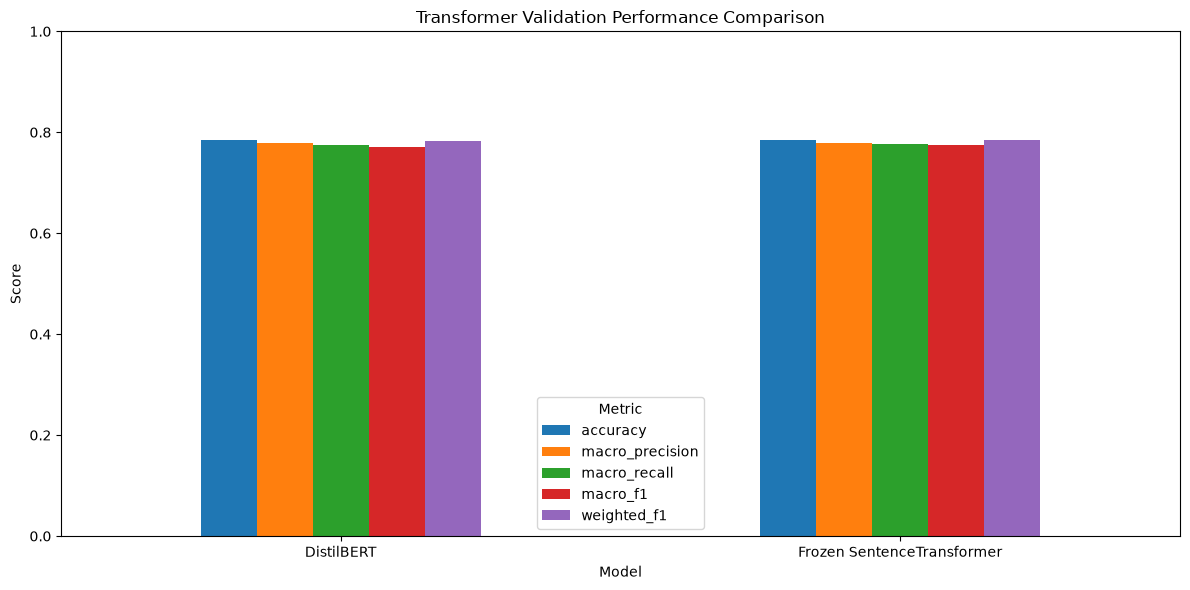

In [16]:
ax = transformer_comparison.T.plot(
    kind="bar",
    figsize=(12, 6),
)

ax.set_title("Transformer Validation Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Metric")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### 6.1 Interpreting Transformer Classification Performance

The comparison shows the relative validation performance of fine-tuned DistilBERT and frozen SentenceTransformer embeddings.

Differences in macro F1 indicate whether one approach provides more balanced classification performance across the 20 categories. Accuracy and weighted F1 provide additional context about overall prediction quality.

The comparison is based on the same training and validation partitions, which makes the results directly comparable within this experiment stage.

The numerical differences should be interpreted alongside the per-class reports and confusion matrices rather than treating one aggregate score as a complete description of model behaviour.


### 6.2 Computational Cost Comparison

Classification performance is only one part of model selection. Computational requirements also influence whether a model is practical to train and deploy.

The following comparison considers the recorded training-related time, inference time, latency, throughput and sampled memory usage.

The measurements have different scopes: DistilBERT includes fine-tuning, whereas the frozen approach includes embedding generation and classifier fitting. The frozen encoder is also excluded from the classifier artifact size.

These distinctions should be retained when interpreting the efficiency results.


In [17]:
efficiency_comparison = pd.DataFrame(
    {
        "DistilBERT": {
            "training_seconds": distilbert_summary.get("training_seconds"),
            "end_to_end_inference_seconds": (
                distilbert_summary.get("end_to_end_inference_seconds")
            ),
            "end_to_end_latency_ms_per_document": (
                distilbert_summary.get("end_to_end_latency_ms_per_document")
            ),
            "end_to_end_throughput_documents_per_second": (
                distilbert_summary.get(
                    "end_to_end_throughput_documents_per_second"
                )
            ),
            "peak_sampled_rss_bytes": (
                distilbert_summary.get("peak_sampled_rss_bytes")
            ),
        },
        "Frozen SentenceTransformer": {
            "training_seconds": (
                frozen_summary.get("training_embedding_seconds", 0)
                + frozen_summary.get("fit_seconds", 0)
            ),
            "end_to_end_inference_seconds": (
                frozen_summary.get("end_to_end_inference_seconds")
            ),
            "end_to_end_latency_ms_per_document": (
                frozen_summary.get("end_to_end_latency_ms_per_document")
            ),
            "end_to_end_throughput_documents_per_second": (
                frozen_summary.get(
                    "end_to_end_throughput_documents_per_second"
                )
            ),
            "peak_sampled_rss_bytes": (
                frozen_summary.get("peak_sampled_rss_bytes")
            ),
        },
    }
)

display(efficiency_comparison)

,DistilBERT,Frozen SentenceTransformer
training_seconds,NaN,6.162222e+02
end_to_end_inference_seconds,2.847786e+02,1.534812e+02
end_to_end_latency_ms_per_document,1.258412e+02,6.782199e+01
end_to_end_throughput_documents_per_second,7.946524e+00,1.474448e+01
peak_sampled_rss_bytes,2.390516e+09,1.743000e+09



### 6.3 Interpreting Computational Efficiency

The efficiency comparison should be interpreted in the context of the different model workflows.

DistilBERT requires gradient-based fine-tuning, whereas the frozen approach performs embedding generation followed by conventional classifier fitting. Both approaches require transformer inference when processing new documents.

Inference measurements include the relevant transformer representation step and classifier prediction where applicable. This provides a more practical comparison than classifier prediction time alone.

Memory figures represent sampled process RSS and include the memory occupied by the running process during the monitored experiment. They should therefore be interpreted as environment-specific observations rather than hardware-independent model requirements.

Artifact sizes also have different scopes. The DistilBERT artifact includes the fine-tuned model and tokenizer, while the frozen-embedding artifact contains the downstream classifier and metadata, excluding the pretrained encoder.


## 7. Experiment Output Verification

The experiment implementations save their results in the locations defined by the transformer configuration.

The saved CSV files contain per-class metrics, while the JSON files preserve experiment summaries and configuration metadata.

The output files are checked here to confirm that both experiments completed and produced the expected records. The stored `test_data_used` field is also checked to verify that neither experiment used the official test partition.


In [18]:
output_paths = {
    "DistilBERT metrics": PROJECT_ROOT / config["outputs"]["distilbert_metrics_csv"],
    "DistilBERT results": PROJECT_ROOT / config["outputs"]["distilbert_results_json"],
    "Frozen embedding metrics": PROJECT_ROOT / config["outputs"]["frozen_metrics_csv"],
    "Frozen embedding results": PROJECT_ROOT / config["outputs"]["frozen_results_json"],
}

for description, path in output_paths.items():
    print(f"{description}: {'Found' if path.is_file() else 'Missing'}")
    print(f"  {path}")

assert all(path.is_file() for path in output_paths.values())

DistilBERT metrics: Found
  /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/transformer_distilbert.csv
DistilBERT results: Found
  /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/transformer_distilbert.json
Frozen embedding metrics: Found
  /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/transformer_frozen_embeddings.csv
Frozen embedding results: Found
  /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/transformer_frozen_embeddings.json


In [19]:
distilbert_saved_results = json.loads(
    output_paths["DistilBERT results"].read_text(encoding="utf-8")
)

frozen_saved_results = json.loads(
    output_paths["Frozen embedding results"].read_text(encoding="utf-8")
)

assert distilbert_saved_results["test_data_used"] is False
assert frozen_saved_results["test_data_used"] is False

print("DistilBERT test data used:", distilbert_saved_results["test_data_used"])
print("Frozen embedding test data used:", frozen_saved_results["test_data_used"])

print("\nSaved experiment identifiers:")
print("DistilBERT:", distilbert_saved_results["experiment_id"])
print("Frozen embeddings:", frozen_saved_results["experiment_id"])

DistilBERT test data used: False
Frozen embedding test data used: False

Saved experiment identifiers:


KeyError: 'experiment_id'

## 8. Experimental Limitations

Several limitations should be considered when interpreting the transformer results.

First, the experiments were conducted using CPU execution. Training duration and inference speed therefore reflect the available hardware and should not be generalised to GPU-based environments.

Second, the DistilBERT experiment uses a deliberately limited training configuration. The results represent the configured fine-tuning experiment rather than an exhaustive search over transformer architectures and hyperparameters.

Third, the frozen-embedding experiment uses one pretrained sentence encoder and one downstream classifier. Other encoders and classification algorithms may produce different results.

Finally, the experiments use a single training and validation split. Although this maintains consistency with the preceding model experiments, repeated runs or additional validation strategies would be needed to assess variation across different partitions and random initialisations.

The official test partition remains reserved for the final evaluation stage.


## 9. Conclusion

This notebook evaluated two transformer-based approaches to supervised topic classification: fine-tuned DistilBERT and frozen SentenceTransformer embeddings combined with Logistic Regression.

The experiments considered classification performance across all 20 categories and examined computational requirements, including training or embedding-generation time, inference efficiency, sampled memory usage and artifact size.

The results provide an additional comparison point alongside the classical machine-learning baselines and neural-network models evaluated earlier in the project.

No final model-selection decision is made solely from these validation results. The findings will be considered together with the earlier experiments and the broader evaluation requirements in the model-comparison stage.

The official test partition remains untouched and will be used only for the final independent evaluation.
